# Machine Learning Modelling

This notebook develops machine learning models to predict fractional vegetation cover (FVC) within the New Acland Coal Mine rehabilitation study area.

Monthly Sentinel-2 vegetation indices (NDVI, EVI and NDRE) and Sentinel-1 SAR backscatter (VV and VH) are used as predictor variables. Landsat-derived FVC is used as the prediction target.

Two predictor configurations are compared:

1. **Optical-only:** NDVI, EVI and NDRE
2. **Optical + SAR:** NDVI, EVI, NDRE, VV and VH

Models are developed for two prediction horizons:

- **1-year prediction:** FVC at *t + 12 months*
- **5-year prediction:** FVC at *t + 60 months*

The purpose of this comparison is to assess whether Sentinel-1 SAR provides additional predictive information beyond Sentinel-2 vegetation indices, and how prediction accuracy changes with increasing prediction horizon.
)

## 1. Load Preprocessed Data

The remote-sensing datasets were preprocessed in the previous notebook and combined onto a common 30 m spatial grid in GDA2020 / MGA Zone 56 (EPSG:7856).

The final dataset contains monthly observations from January 2016 to December 2025. It includes three Sentinel-2 vegetation indices, two Sentinel-1 SAR variables, and Landsat-derived FVC.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import json

from shapely.geometry import shape
from rasterio.features import geometry_mask
from affine import Affine
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
model_data = xr.open_dataset(
    "model_data_2016_2025.nc"
)

print(model_data)

<xarray.Dataset> Size: 149MB
Dimensions:      (time: 120, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
Data variables:
    NDVI         (time, y, x) float32 19MB ...
    EVI          (time, y, x) float32 19MB ...
    NDRE         (time, y, x) float32 19MB ...
    VV           (time, y, x) float64 37MB ...
    VH           (time, y, x) float64 37MB ...
    FVC          (time, y, x) float32 19MB ...
    spatial_ref  int32 4B ...


### Dataset Structure

The dataset contains 120 monthly time steps from January 2016 to December 2025.

Predictor variables include:

- **NDVI:** Normalised Difference Vegetation Index
- **EVI:** Enhanced Vegetation Index
- **NDRE:** Normalised Difference Red Edge Index
- **VV:** Sentinel-1 VV backscatter
- **VH:** Sentinel-1 VH backscatter

The target variable is:

- **FVC:** Fractional Vegetation Cover (%)

Although all variables have been aligned to the same 30 m grid, the dataset currently covers the rectangular bounding extent of the study area. The exact study-area polygon is therefore applied before constructing the machine learning samples.

## 2. Apply Study Area Mask

The preprocessed dataset covers a rectangular spatial extent surrounding the New Acland study area. However, the rehabilitation analysis should only include pixels located within the defined study-area polygon.

The original study-area polygon is therefore loaded and rasterised onto the 30 m analysis grid. This creates a Boolean spatial mask that identifies pixels located inside the study area. The same mask is then applied consistently to all predictor and target variables.

In [3]:
with open("Study_site_output.json", "r") as f:
    study_json = json.load(f)

geometry = shape(
    study_json["features"][0]["geometry"]
)

study_area = gpd.GeoDataFrame(
    geometry=[geometry],
    crs="EPSG:7856"
)

print(study_area)
print("Study area CRS:", study_area.crs)

                                            geometry
0  POLYGON ((374924.605 6977342.786, 374942.03 69...
Study area CRS: EPSG:7856


### Rasterise the Study Area

The polygon is rasterised using the coordinates of the 30 m modelling grid. Pixels whose centres fall within the study-area polygon are assigned `True`, while pixels outside the polygon are assigned `False`.

This ensures that subsequent machine learning samples are restricted to the intended mine rehabilitation study area rather than the full rectangular raster extent.

In [4]:
# Calculate grid resolution
x_res = float(model_data.x.values[1] - model_data.x.values[0])
y_res = float(model_data.y.values[1] - model_data.y.values[0])

print("X resolution:", x_res)
print("Y resolution:", y_res)

X resolution: 30.0
Y resolution: -30.0


In [5]:
# Construct the affine transform for the 30 m grid
transform = Affine(
    x_res,
    0,
    model_data.x.values[0] - x_res / 2,
    0,
    y_res,
    model_data.y.values[0] - y_res / 2
)

# Rasterise the study-area polygon
study_mask_array = geometry_mask(
    [study_area.geometry.iloc[0]],
    out_shape=(
        model_data.sizes["y"],
        model_data.sizes["x"]
    ),
    transform=transform,
    invert=True
)

# Convert the mask to an xarray DataArray
study_mask_30m = xr.DataArray(
    study_mask_array,
    coords={
        "y": model_data.y,
        "x": model_data.x
    },
    dims=("y", "x"),
    name="study_area_mask"
)

print(study_mask_30m)

<xarray.DataArray 'study_area_mask' (y: 216, x: 180)> Size: 39kB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(216, 180))
Coordinates:
  * y        (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
  * x        (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05


### Check the Study Area Mask

The number and area of pixels included in the rasterised study-area mask are calculated to confirm that the polygon has been transferred correctly to the 30 m modelling grid.

In [6]:
n_study_pixels = int(study_mask_30m.sum())

pixel_area_m2 = abs(x_res * y_res)
study_area_m2 = n_study_pixels * pixel_area_m2
study_area_km2 = study_area_m2 / 1_000_000

print("Study-area pixels:", n_study_pixels)
print(
    "Approximate rasterised area:",
    round(study_area_km2, 2),
    "km²"
)

Study-area pixels: 28145
Approximate rasterised area: 25.33 km²


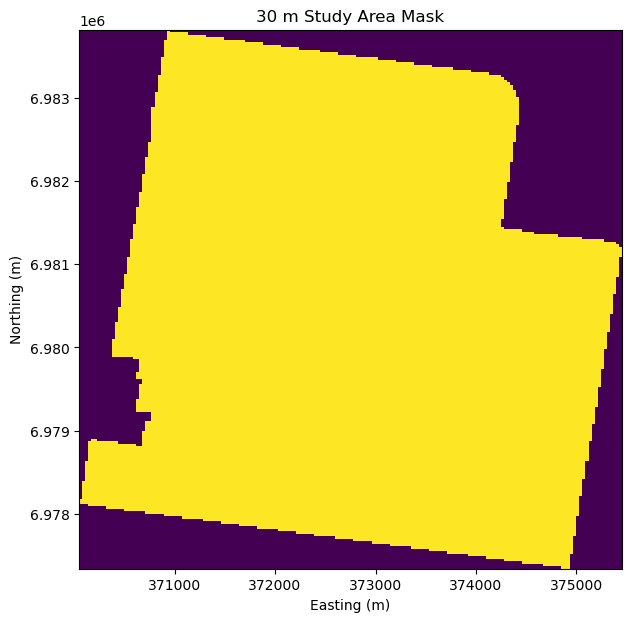

In [7]:
plt.figure(figsize=(7, 7))

study_mask_30m.plot(
    add_colorbar=False
)

plt.title("30 m Study Area Mask")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")

plt.show()

### Apply the Spatial Mask

The study-area mask is applied to the complete modelling dataset. Pixels outside the polygon are converted to `NaN`, while observations within the study area are retained.

The temporal dimension and original predictor and target variables remain unchanged.

In [8]:
model_data_masked = model_data.where(
    study_mask_30m
)

print(model_data_masked)

<xarray.Dataset> Size: 150MB
Dimensions:      (time: 120, y: 216, x: 180)
Coordinates:
  * time         (time) datetime64[ns] 960B 2016-01-01 2016-02-01 ... 2025-12-01
  * x            (x) float64 1kB 3.701e+05 3.701e+05 ... 3.754e+05 3.754e+05
  * y            (y) float64 2kB 6.984e+06 6.984e+06 ... 6.977e+06 6.977e+06
Data variables:
    NDVI         (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    EVI          (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    NDRE         (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    VV           (time, y, x) float64 37MB nan nan nan nan ... nan nan nan nan
    VH           (time, y, x) float64 37MB nan nan nan nan ... nan nan nan nan
    FVC          (time, y, x) float32 19MB nan nan nan nan ... nan nan nan nan
    spatial_ref  (y, x) float64 311kB nan nan nan nan nan ... nan nan nan nan


In [9]:
print("Study-area mask pixels:", n_study_pixels)

for var in [
    "NDVI",
    "EVI",
    "NDRE",
    "VV",
    "VH",
    "FVC"
]:
    valid_pixels = (
        model_data_masked[var]
        .notnull()
        .any(dim="time")
        .sum()
        .item()
    )

    print(
        f"{var}: {valid_pixels} pixels "
        f"with at least one valid observation"
    )

Study-area mask pixels: 28145
NDVI: 27037 pixels with at least one valid observation
EVI: 27037 pixels with at least one valid observation
NDRE: 27037 pixels with at least one valid observation
VV: 24414 pixels with at least one valid observation
VH: 24414 pixels with at least one valid observation
FVC: 28145 pixels with at least one valid observation


### Study Area Mask Results

The rasterised study-area mask contains 28,145 pixels at 30 m spatial resolution, corresponding to an approximate area of 25.33 km².

FVC observations cover the entire study area, while the Sentinel-2 and Sentinel-1 predictors have slightly smaller valid spatial extents. These differences are retained at this stage rather than removing pixels globally. Valid observations will instead be selected when constructing the machine learning samples for each prediction horizon.

For the final comparison between the optical-only and optical-plus-SAR models, identical samples will be used to ensure that differences in model performance reflect the contribution of SAR predictors rather than differences in sample availability.

## 3. Construct Future FVC Prediction Targets

The modelling framework uses Earth observation variables observed at month *t* to predict FVC at a future date.

Two prediction horizons are evaluated:

- **1-year horizon:** predictors at *t* → FVC at *t + 12 months*
- **5-year horizon:** predictors at *t* → FVC at *t + 60 months*

Target dates are matched using actual calendar dates rather than row positions. This preserves the correct temporal relationship even when individual predictor variables contain missing months.

In [10]:
# Predictor dates available in the dataset
all_dates = pd.DatetimeIndex(model_data_masked.time.values)

# Create valid predictor-target date pairs
pairs_1yr = []

for predictor_date in all_dates:
    target_date = predictor_date + pd.DateOffset(months=12)

    if target_date in all_dates:
        pairs_1yr.append(
            (predictor_date, target_date)
        )

pairs_5yr = []

for predictor_date in all_dates:
    target_date = predictor_date + pd.DateOffset(months=60)

    if target_date in all_dates:
        pairs_5yr.append(
            (predictor_date, target_date)
        )

print("1-year date pairs:", len(pairs_1yr))
print("5-year date pairs:", len(pairs_5yr))

print("\n1-year:")
print("First:", pairs_1yr[0])
print("Last: ", pairs_1yr[-1])

print("\n5-year:")
print("First:", pairs_5yr[0])
print("Last: ", pairs_5yr[-1])

1-year date pairs: 108
5-year date pairs: 60

1-year:
First: (Timestamp('2016-01-01 00:00:00'), Timestamp('2017-01-01 00:00:00'))
Last:  (Timestamp('2024-12-01 00:00:00'), Timestamp('2025-12-01 00:00:00'))

5-year:
First: (Timestamp('2016-01-01 00:00:00'), Timestamp('2021-01-01 00:00:00'))
Last:  (Timestamp('2020-12-01 00:00:00'), Timestamp('2025-12-01 00:00:00'))


### Construct Machine Learning Samples

Each valid pixel-month observation is converted into an individual machine learning sample. Predictor values are extracted at the predictor date (*t*), while FVC is extracted from the corresponding future target date.

The selected predictor and target arrays retain only their spatial dimensions (`y` and `x`). Predictor and target dates are stored separately for each observation, allowing the temporal relationship to be preserved without creating coordinate conflicts.

Only observations containing valid values for all five predictors and future FVC are retained. This produces a common sample dataset that can later be used for a fair comparison between the optical-only and optical-plus-SAR models.

In [11]:
def build_ml_samples(dataset, date_pairs):
    sample_list = []

    for predictor_date, target_date in date_pairs:

        predictors = dataset[
            ["NDVI", "EVI", "NDRE", "VV", "VH"]
        ].sel(
            time=predictor_date,
            drop=True
        )

        target = dataset["FVC"].sel(
            time=target_date,
            drop=True
        )

        sample = xr.Dataset({
            "NDVI": predictors["NDVI"],
            "EVI": predictors["EVI"],
            "NDRE": predictors["NDRE"],
            "VV": predictors["VV"],
            "VH": predictors["VH"],
            "FVC_target": target
        })

        df = sample.to_dataframe().reset_index()

        df["predictor_date"] = predictor_date
        df["target_date"] = target_date

        sample_list.append(df)

    samples = pd.concat(
        sample_list,
        ignore_index=True
    )

    samples = samples.dropna(
        subset=[
            "NDVI",
            "EVI",
            "NDRE",
            "VV",
            "VH",
            "FVC_target"
        ]
    )

    return samples

### Generate 1-Year and 5-Year Sample Datasets

The sampling function is applied separately to the two prediction horizons. Observations are retained only when all optical predictors, SAR predictors and the future FVC target are available.

In [12]:
samples_1yr = build_ml_samples(
    model_data_masked,
    pairs_1yr
)

samples_5yr = build_ml_samples(
    model_data_masked,
    pairs_5yr
)

print("1-year samples:", len(samples_1yr))
print("5-year samples:", len(samples_5yr))

1-year samples: 2431453
5-year samples: 1342009


In [13]:
print("1-year samples")
print("----------------")
print("Samples:", len(samples_1yr))
print(
    "Predictor dates:",
    samples_1yr["predictor_date"].nunique()
)
print(
    "Target dates:",
    samples_1yr["target_date"].nunique()
)
print(
    "Unique spatial locations:",
    samples_1yr[["x", "y"]]
    .drop_duplicates()
    .shape[0]
)

print("\n5-year samples")
print("----------------")
print("Samples:", len(samples_5yr))
print(
    "Predictor dates:",
    samples_5yr["predictor_date"].nunique()
)
print(
    "Target dates:",
    samples_5yr["target_date"].nunique()
)
print(
    "Unique spatial locations:",
    samples_5yr[["x", "y"]]
    .drop_duplicates()
    .shape[0]
)

1-year samples
----------------
Samples: 2431453
Predictor dates: 105
Target dates: 105
Unique spatial locations: 24224

5-year samples
----------------
Samples: 1342009
Predictor dates: 58
Target dates: 58
Unique spatial locations: 23884


### Sample Availability

After removing observations with missing predictor or target values, the 1-year dataset contains 105 valid predictor months and the 5-year dataset contains 58 valid predictor months.

The reduction in temporal coverage is caused by completely missing predictor months. Sentinel-2 data are unavailable for March 2016 and February 2020, while Sentinel-1 data are unavailable for January 2024. Because January 2024 falls outside the predictor period of the 5-year model, it only affects the 1-year dataset.

The resulting datasets contain approximately 2.43 million observations for the 1-year prediction horizon and 1.34 million observations for the 5-year prediction horizon.

### Check Predictor and Target Ranges

Summary statistics are examined before model development to identify unexpected values and confirm that the machine learning samples retain physically plausible predictor and target ranges.

In [14]:
variables = [
    "NDVI",
    "EVI",
    "NDRE",
    "VV",
    "VH",
    "FVC_target"
]

print("1-year samples")
display(
    samples_1yr[variables]
    .describe()
    .round(3)
)

print("\n5-year samples")
display(
    samples_5yr[variables]
    .describe()
    .round(3)
)

1-year samples


,NDVI,EVI,NDRE,VV,VH,FVC_target
count,2431453.000,2431453.000,2431453.000,2431453.000,2431453.000,2431453.000
mean,0.338,0.191,0.216,-12.247,-19.742,80.028
std,0.194,0.121,0.130,2.302,3.097,14.457
min,-0.624,-0.213,-0.574,-34.062,-44.414,0.000
25%,0.175,0.094,0.117,-13.499,-21.562,74.000
50%,0.334,0.175,0.215,-12.271,-19.327,84.500
75%,0.484,0.267,0.309,-11.029,-17.589,90.000
max,0.893,0.862,0.690,5.797,3.580,100.000



5-year samples


,NDVI,EVI,NDRE,VV,VH,FVC_target
count,1342009.000,1342009.000,1342009.000,1342009.000,1342009.000,1342009.000
mean,0.290,0.160,0.184,-12.434,-20.349,83.342
std,0.179,0.106,0.122,2.291,3.143,12.294
min,-0.624,-0.198,-0.574,-31.511,-44.400,0.000
25%,0.138,0.076,0.093,-13.738,-22.243,80.000
50%,0.276,0.142,0.177,-12.484,-19.939,87.000
75%,0.419,0.224,0.269,-11.202,-18.098,91.000
max,0.893,0.862,0.687,5.797,3.580,100.000


In [15]:
print("Missing values — 1-year")
print(samples_1yr[variables].isna().sum())

print("\nMissing values — 5-year")
print(samples_5yr[variables].isna().sum())

Missing values — 1-year
NDVI          0
EVI           0
NDRE          0
VV            0
VH            0
FVC_target    0
dtype: int64

Missing values — 5-year
NDVI          0
EVI           0
NDRE          0
VV            0
VH            0
FVC_target    0
dtype: int64


## 4. Model Validation Strategy

Remote-sensing observations exhibit both spatial and temporal autocorrelation. Adjacent pixels may have similar environmental characteristics, while repeated observations of the same location through time are not statistically independent.

A conventional random train-test split could therefore place observations from the same or nearby locations in both the training and testing datasets, resulting in information leakage and overly optimistic estimates of model performance.

To reduce this problem, model validation is based on spatial blocks. The study area is divided into larger spatial units, and entire blocks are assigned to either training or testing. This ensures that test pixels are spatially separated from pixels used to train the model.

The same spatial split is applied to the optical-only and optical-plus-SAR models so that their performance can be compared directly.

### Create Spatial Blocks

The study area is divided into approximately 500 m × 500 m spatial blocks using the projected MGA coordinates of each pixel.

Rather than assigning individual pixels randomly, complete spatial blocks are allocated to the training or testing dataset. Approximately 20% of the spatial blocks are reserved for independent testing.

In [16]:
block_size = 500

def add_spatial_blocks(samples, block_size=500):
    samples = samples.copy()

    samples["block_x"] = (
        samples["x"] // block_size
    ).astype(int)

    samples["block_y"] = (
        samples["y"] // block_size
    ).astype(int)

    samples["block_id"] = (
        samples["block_x"].astype(str)
        + "_"
        + samples["block_y"].astype(str)
    )

    return samples


samples_1yr = add_spatial_blocks(
    samples_1yr,
    block_size
)

samples_5yr = add_spatial_blocks(
    samples_5yr,
    block_size
)

print(
    "1-year spatial blocks:",
    samples_1yr["block_id"].nunique()
)

print(
    "5-year spatial blocks:",
    samples_5yr["block_id"].nunique()
)

1-year spatial blocks: 108
5-year spatial blocks: 107


### Inspect Spatial Block Distribution

Before assigning blocks to training and testing datasets, the spatial block structure is examined to confirm that the selected block size produces a sufficient number of independent spatial units across the study area.

In [17]:
block_summary_1yr = (
    samples_1yr[
        ["block_id", "block_x", "block_y"]
    ]
    .drop_duplicates()
)

block_summary_5yr = (
    samples_5yr[
        ["block_id", "block_x", "block_y"]
    ]
    .drop_duplicates()
)

print("1-year blocks:")
print(block_summary_1yr.shape[0])

print("\n5-year blocks:")
print(block_summary_5yr.shape[0])

1-year blocks:
108

5-year blocks:
107


### Define Common Training and Testing Blocks

To improve comparability between the 1-year and 5-year prediction models, spatial blocks that occur in both datasets are identified.

A fixed random seed is then used to assign approximately 20% of these common spatial blocks to the testing dataset. All observations within a selected test block are excluded from model training.

Using the same test blocks across prediction horizons provides a more consistent basis for comparing model performance.

In [18]:
# Identify spatial blocks shared by both prediction horizons
common_blocks = np.intersect1d(
    samples_1yr["block_id"].unique(),
    samples_5yr["block_id"].unique()
)

print("Common spatial blocks:", len(common_blocks))

Common spatial blocks: 107


In [19]:
# Reproducible spatial train-test split
rng = np.random.default_rng(42)

n_test_blocks = round(
    len(common_blocks) * 0.20
)

test_blocks = rng.choice(
    common_blocks,
    size=n_test_blocks,
    replace=False
)

train_blocks = np.setdiff1d(
    common_blocks,
    test_blocks
)

print("Training blocks:", len(train_blocks))
print("Testing blocks:", len(test_blocks))

Training blocks: 86
Testing blocks: 21


### Apply the Spatial Split

Observations are assigned to training or testing datasets according to their spatial block. Entire test blocks are withheld from training, ensuring that no pixel from a test block is used during model fitting.

Only spatial blocks shared by both prediction horizons are retained to maintain a consistent spatial validation extent.

In [20]:
train_1yr = samples_1yr[
    samples_1yr["block_id"].isin(train_blocks)
].copy()

test_1yr = samples_1yr[
    samples_1yr["block_id"].isin(test_blocks)
].copy()

train_5yr = samples_5yr[
    samples_5yr["block_id"].isin(train_blocks)
].copy()

test_5yr = samples_5yr[
    samples_5yr["block_id"].isin(test_blocks)
].copy()

In [21]:
print("1-year model")
print("----------------")
print("Training samples:", len(train_1yr))
print("Testing samples:", len(test_1yr))
print(
    "Training blocks:",
    train_1yr["block_id"].nunique()
)
print(
    "Testing blocks:",
    test_1yr["block_id"].nunique()
)

print("\n5-year model")
print("----------------")
print("Training samples:", len(train_5yr))
print("Testing samples:", len(test_5yr))
print(
    "Training blocks:",
    train_5yr["block_id"].nunique()
)
print(
    "Testing blocks:",
    test_5yr["block_id"].nunique()
)

1-year model
----------------
Training samples: 1912827
Testing samples: 518615
Training blocks: 86
Testing blocks: 21

5-year model
----------------
Training samples: 1055820
Testing samples: 286189
Training blocks: 86
Testing blocks: 21


In [22]:
overlap_1yr = set(
    train_1yr["block_id"]
).intersection(
    set(test_1yr["block_id"])
)

overlap_5yr = set(
    train_5yr["block_id"]
).intersection(
    set(test_5yr["block_id"])
)

print(
    "Overlapping blocks — 1-year:",
    len(overlap_1yr)
)

print(
    "Overlapping blocks — 5-year:",
    len(overlap_5yr)
)

Overlapping blocks — 1-year: 0
Overlapping blocks — 5-year: 0


## 5. Random Forest Modelling

Random Forest regression is used to predict future fractional vegetation cover (FVC). Two predictor configurations are evaluated for each prediction horizon:

- **Optical-only model:** NDVI, EVI and NDRE
- **Optical + SAR model:** NDVI, EVI, NDRE, VV and VH

The same training and testing observations are used for both predictor configurations within each prediction horizon. This allows changes in predictive performance to be attributed to the inclusion of Sentinel-1 SAR variables.

Because the spatial-temporal dataset contains more than one million training observations and many observations are spatially and temporally correlated, a subset of the training data is used for model fitting to reduce computational demand. The independent spatial test blocks are retained in full for model evaluation.

### Prepare Training Samples

A maximum of 200,000 observations is randomly sampled from each training dataset using a fixed random seed. The same sampled observations are subsequently used for the optical-only and optical-plus-SAR models.

In [23]:
train_sample_size = 200_000
random_seed = 42

train_1yr_sample = train_1yr.sample(
    n=min(train_sample_size, len(train_1yr)),
    random_state=random_seed
)

train_5yr_sample = train_5yr.sample(
    n=min(train_sample_size, len(train_5yr)),
    random_state=random_seed
)

print("1-year training sample:", len(train_1yr_sample))
print("5-year training sample:", len(train_5yr_sample))

print(
    "1-year blocks represented:",
    train_1yr_sample["block_id"].nunique()
)

print(
    "5-year blocks represented:",
    train_5yr_sample["block_id"].nunique()
)

1-year training sample: 200000
5-year training sample: 200000
1-year blocks represented: 86
5-year blocks represented: 86


### Define Predictor Configurations

Two sets of predictor variables are defined to quantify the contribution of Sentinel-1 SAR data.

The optical-only configuration contains the three Sentinel-2 vegetation indices. The optical-plus-SAR configuration adds VV and VH backscatter to the same optical predictors.

In [24]:
optical_features = [
    "NDVI",
    "EVI",
    "NDRE"
]

optical_sar_features = [
    "NDVI",
    "EVI",
    "NDRE",
    "VV",
    "VH"
]

target_variable = "FVC_target"

### Model Training and Evaluation Function

A common modelling function is used to ensure that all four model configurations are trained and evaluated consistently.

Model performance is evaluated using:

- **MAE:** mean absolute error in predicted FVC percentage points
- **RMSE:** root mean squared error, which gives greater weight to larger prediction errors
- **R²:** proportion of variation in future FVC explained by the model

In [25]:
def train_evaluate_rf(
    train_data,
    test_data,
    features,
    n_estimators=100
):
    X_train = train_data[features]
    y_train = train_data[target_variable]

    X_test = test_data[features]
    y_test = test_data[target_variable]

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    metrics = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    return model, predictions, metrics

### 1-Year Optical-Only Baseline

The first baseline model uses only Sentinel-2 vegetation indices to predict FVC one year into the future.

In [26]:
rf_1yr_optical, pred_1yr_optical, metrics_1yr_optical = (
    train_evaluate_rf(
        train_1yr_sample,
        test_1yr,
        optical_features
    )
)

print("1-year Optical-only")
print("--------------------")

for metric, value in metrics_1yr_optical.items():
    print(f"{metric}: {value:.3f}")

1-year Optical-only
--------------------
MAE: 7.995
RMSE: 11.173
R2: 0.316


### 1-Year Optical + SAR Model

The second 1-year model adds Sentinel-1 VV and VH backscatter to the Sentinel-2 vegetation indices.

The training observations, spatial test blocks and Random Forest parameters are kept identical to the optical-only model. Therefore, differences in model performance can be used to evaluate the additional predictive contribution of SAR data.

In [27]:
rf_1yr_sar, pred_1yr_sar, metrics_1yr_sar = (
    train_evaluate_rf(
        train_1yr_sample,
        test_1yr,
        optical_sar_features
    )
)

print("1-year Optical + SAR")
print("--------------------")

for metric, value in metrics_1yr_sar.items():
    print(f"{metric}: {value:.3f}")

1-year Optical + SAR
--------------------
MAE: 7.757
RMSE: 10.891
R2: 0.350


### Effect of Adding Sentinel-1 SAR

The performance of the optical-only and optical-plus-SAR models is compared using the same independent spatial test dataset.

For MAE and RMSE, the percentage change is calculated relative to the optical-only model, with positive values indicating a reduction in prediction error and negative values indicating an increase in prediction error. For R², the absolute difference between the optical-plus-SAR and optical-only models is reported.

This comparison does not assume that adding SAR will improve model performance; the direction of change is determined from the model results.

In [28]:
results_1yr = {
    "Optical": metrics_1yr_optical.copy(),
    "Optical_SAR": metrics_1yr_sar.copy()
}

print(results_1yr)

{'Optical': {'MAE': 7.995029665551516, 'RMSE': np.float64(11.172975276203797), 'R2': 0.31638743429857064}, 'Optical_SAR': {'MAE': 7.757369561235212, 'RMSE': np.float64(10.890714079164967), 'R2': 0.3504911480777576}}


In [29]:
mae_change_1yr = (
    (results_1yr["Optical"]["MAE"]
     - results_1yr["Optical_SAR"]["MAE"])
    / results_1yr["Optical"]["MAE"]
    * 100
)

rmse_change_1yr = (
    (results_1yr["Optical"]["RMSE"]
     - results_1yr["Optical_SAR"]["RMSE"])
    / results_1yr["Optical"]["RMSE"]
    * 100
)

r2_change_1yr = (
    results_1yr["Optical_SAR"]["R2"]
    - results_1yr["Optical"]["R2"]
)

print("1-year change after adding SAR")
print("------------------------------")
print(f"MAE change:  {mae_change_1yr:+.2f}%")
print(f"RMSE change: {rmse_change_1yr:+.2f}%")
print(f"R² change:   {r2_change_1yr:+.3f}")

1-year change after adding SAR
------------------------------
MAE change:  +2.97%
RMSE change: +2.53%
R² change:   +0.034


### Memory Management

The complete pixel-month datasets contain several million observations and require substantial memory. Intermediate objects that are no longer required are removed before training the remaining models to reduce memory usage in the DEA environment.

In [30]:
del rf_1yr_optical
del rf_1yr_sar

del pred_1yr_optical
del pred_1yr_sar

del samples_1yr
del train_1yr
del test_1yr
del train_1yr_sample

In [31]:
import gc

gc.collect()


87

### Reduce Memory Before 5-Year Modelling

The 5-year training subset and independent test dataset have already been created. The larger intermediate 5-year sample and training datasets are therefore no longer required and are removed before model fitting.

In [32]:
del samples_5yr
del train_5yr

# Other intermediate tables are no longer required
del block_summary_1yr
del block_summary_5yr

gc.collect()

0

In [33]:
print("5-year training sample:", len(train_5yr_sample))
print("5-year test samples:", len(test_5yr))

print(
    "Training blocks:",
    train_5yr_sample["block_id"].nunique()
)

print(
    "Testing blocks:",
    test_5yr["block_id"].nunique()
)

5-year training sample: 200000
5-year test samples: 286189
Training blocks: 86
Testing blocks: 21


### 5-Year Optical-Only Model

The optical-only Random Forest model uses NDVI, EVI and NDRE at time *t* to predict FVC five years later. The same Random Forest configuration and spatial block validation strategy used for the 1-year model are retained.

In [34]:
rf_5yr_optical, pred_5yr_optical, metrics_5yr_optical = (
    train_evaluate_rf(
        train_5yr_sample,
        test_5yr,
        optical_features
    )
)

print("5-year Optical-only")
print("--------------------")

for metric, value in metrics_5yr_optical.items():
    print(f"{metric}: {value:.3f}")

5-year Optical-only
--------------------
MAE: 7.440
RMSE: 10.696
R2: 0.069


### 5-Year Optical-Only Performance

The 5-year optical-only model achieved an MAE of 7.440 percentage points, an RMSE of 10.696 percentage points, and an R² of 0.069.

Although MAE and RMSE were slightly lower than for the 1-year optical model, the substantially lower R² indicates that the optical predictors explain considerably less of the spatial variation in FVC at the 5-year prediction horizon. The lower absolute errors should be interpreted in the context of the narrower distribution of the 5-year FVC target.

In [35]:
metrics_5yr_optical_saved = (
    metrics_5yr_optical.copy()
)

del rf_5yr_optical
del pred_5yr_optical

gc.collect()

58

### 5-Year Optical + SAR Model

The final baseline model adds Sentinel-1 VV and VH backscatter to the optical predictors for the 5-year prediction horizon. Performance is evaluated using the same training observations and independent spatial test blocks as the optical-only model.

In [36]:
rf_5yr_sar, pred_5yr_sar, metrics_5yr_sar = (
    train_evaluate_rf(
        train_5yr_sample,
        test_5yr,
        optical_sar_features
    )
)

print("5-year Optical + SAR")
print("--------------------")

for metric, value in metrics_5yr_sar.items():
    print(f"{metric}: {value:.3f}")

5-year Optical + SAR
--------------------
MAE: 7.265
RMSE: 10.474
R2: 0.107


In [37]:
mae_change_5yr = (
    (
        metrics_5yr_optical_saved["MAE"]
        - metrics_5yr_sar["MAE"]
    )
    / metrics_5yr_optical_saved["MAE"]
    * 100
)

rmse_change_5yr = (
    (
        metrics_5yr_optical_saved["RMSE"]
        - metrics_5yr_sar["RMSE"]
    )
    / metrics_5yr_optical_saved["RMSE"]
    * 100
)

r2_change_5yr = (
    metrics_5yr_sar["R2"]
    - metrics_5yr_optical_saved["R2"]
)

print("5-year change after adding SAR")
print("------------------------------")
print(f"MAE change:  {mae_change_5yr:+.2f}%")
print(f"RMSE change: {rmse_change_5yr:+.2f}%")
print(f"R² change:   {r2_change_5yr:+.3f}")

5-year change after adding SAR
------------------------------
MAE change:  +2.34%
RMSE change: +2.08%
R² change:   +0.038


### Baseline Model Results

The baseline models show that adding Sentinel-1 SAR predictors improved model performance at both prediction horizons.

For the 1-year prediction, adding VV and VH reduced MAE by 2.97% and RMSE by 2.53%, while R² increased from 0.316 to 0.350 (+0.034).

For the 5-year prediction, adding VV and VH reduced MAE by 2.34% and RMSE by 2.08%, while R² increased from 0.069 to 0.107 (+0.038).

These results provide initial evidence that Sentinel-1 SAR contributes additional predictive information beyond the Sentinel-2 vegetation indices. However, these results are based on a single spatial train-test split and should therefore be treated as baseline results rather than evidence that the improvement is consistent across all spatial partitions.

The substantially lower R² for the 5-year models also indicates that the explanatory power of the current EO conditions decreases considerably at the longer prediction horizon.

In [38]:
baseline_results = pd.DataFrame({
    "Horizon": [
        "1-year",
        "1-year",
        "5-year",
        "5-year"
    ],
    "Model": [
        "Optical",
        "Optical + SAR",
        "Optical",
        "Optical + SAR"
    ],
    "MAE": [
        results_1yr["Optical"]["MAE"],
        results_1yr["Optical_SAR"]["MAE"],
        metrics_5yr_optical_saved["MAE"],
        metrics_5yr_sar["MAE"]
    ],
    "RMSE": [
        results_1yr["Optical"]["RMSE"],
        results_1yr["Optical_SAR"]["RMSE"],
        metrics_5yr_optical_saved["RMSE"],
        metrics_5yr_sar["RMSE"]
    ],
    "R2": [
        results_1yr["Optical"]["R2"],
        results_1yr["Optical_SAR"]["R2"],
        metrics_5yr_optical_saved["R2"],
        metrics_5yr_sar["R2"]
    ]
})

display(
    baseline_results.round(3)
)

,Horizon,Model,MAE,RMSE,R2
0,1-year,Optical,7.995,11.173,0.316
1,1-year,Optical + SAR,7.757,10.891,0.350
2,5-year,Optical,7.440,10.696,0.069
3,5-year,Optical + SAR,7.265,10.474,0.107


In [39]:
baseline_results.to_csv(
    "baseline_model_results.csv",
    index=False
)

print("Baseline results saved.")

Baseline results saved.


In [40]:
del rf_5yr_sar
del pred_5yr_sar

gc.collect()

29

### Baseline Model Summary

The four baseline models show two main patterns.

First, the inclusion of Sentinel-1 SAR improved model performance at both prediction horizons. For the 1-year prediction, adding VV and VH reduced MAE from 7.995 to 7.757 and RMSE from 11.173 to 10.891, while R² increased from 0.316 to 0.350. For the 5-year prediction, MAE decreased from 7.440 to 7.265 and RMSE from 10.696 to 10.474, while R² increased from 0.069 to 0.107.

Second, R² was substantially lower for the 5-year models than for the corresponding 1-year models. This indicates that the current EO conditions have considerably lower explanatory power for FVC five years into the future.

These results provide initial evidence that Sentinel-1 SAR contributes additional predictive information beyond the Sentinel-2 vegetation indices. However, the results are based on a single spatial train-test split and the consistency of this improvement should be further evaluated using spatial cross-validation.

## 6. Spatial Block Cross-Validation

The baseline models were evaluated using a single spatial train-test split. Model performance may therefore depend on which spatial blocks were selected for testing.

To assess the robustness of the results, 5-fold spatial block cross-validation is applied. Entire 500 m spatial blocks are assigned to folds so that observations from the same spatial block cannot occur in both the training and validation datasets within a fold.

For each fold, optical-only and optical-plus-SAR Random Forest models are trained using identical observations and evaluated on the same withheld spatial blocks. This allows the contribution of Sentinel-1 SAR to be assessed across multiple independent spatial partitions.

### Reconstruct 1-Year Samples for Cross-Validation

The 1-year pixel-month samples are reconstructed and assigned to the previously defined 500 m spatial blocks. Only observations containing valid values for all optical, SAR and target variables are retained.

In [41]:
samples_1yr_cv = build_ml_samples(
    model_data_masked,
    pairs_1yr
)

samples_1yr_cv = add_spatial_blocks(
    samples_1yr_cv,
    block_size=500
)

print("Samples:", len(samples_1yr_cv))
print(
    "Spatial blocks:",
    samples_1yr_cv["block_id"].nunique()
)

Samples: 2431453
Spatial blocks: 108


### Define Spatial Cross-Validation Folds

Five spatial folds are generated using the 500 m block identifiers as grouping variables. Group-based splitting ensures that all observations belonging to the same spatial block remain within a single fold.

In [42]:
from sklearn.model_selection import GroupKFold

group_kfold = GroupKFold(
    n_splits=5
)

groups_1yr = samples_1yr_cv["block_id"]

fold_info = []

for fold, (train_idx, test_idx) in enumerate(
    group_kfold.split(
        samples_1yr_cv,
        groups=groups_1yr
    ),
    start=1
):
    train_blocks_fold = (
        samples_1yr_cv.iloc[train_idx]["block_id"]
        .nunique()
    )

    test_blocks_fold = (
        samples_1yr_cv.iloc[test_idx]["block_id"]
        .nunique()
    )

    fold_info.append({
        "Fold": fold,
        "Training blocks": train_blocks_fold,
        "Testing blocks": test_blocks_fold,
        "Training observations": len(train_idx),
        "Testing observations": len(test_idx)
    })

fold_info = pd.DataFrame(fold_info)

display(fold_info)

,Fold,Training blocks,Testing blocks,Training observations,Testing observations
0,1,86,22,1944655,486798
1,2,87,21,1945458,485995
2,3,86,22,1944724,486729
3,4,86,22,1945547,485906
4,5,87,21,1945428,486025


### Cross-Validation Model Evaluation

Within each fold, a maximum of 200,000 observations is randomly selected from the training blocks to maintain computational feasibility. The complete withheld validation fold is retained for evaluation.

Both predictor configurations use exactly the same sampled training observations and validation observations within each fold.

In [43]:
def spatial_cv_rf(
    samples,
    features_optical,
    features_sar,
    n_splits=5,
    train_sample_size=200_000,
    n_estimators=100,
    random_seed=42
):
    groups = samples["block_id"]

    gkf = GroupKFold(
        n_splits=n_splits
    )

    results = []

    for fold, (train_idx, test_idx) in enumerate(
        gkf.split(samples, groups=groups),
        start=1
    ):

        print(f"\nFold {fold}/{n_splits}")

        # Randomly sample training indices directly
        rng = np.random.default_rng(
            random_seed + fold
        )

        if len(train_idx) > train_sample_size:
            train_idx_sample = rng.choice(
                train_idx,
                size=train_sample_size,
                replace=False
            )
        else:
            train_idx_sample = train_idx

        train_fold = samples.iloc[
            train_idx_sample
        ]

        test_fold = samples.iloc[
            test_idx
        ]

        print(
            "Training samples:",
            len(train_fold)
        )
        print(
            "Testing samples:",
            len(test_fold)
        )

        # Optical-only model
        rf_optical = RandomForestRegressor(
            n_estimators=n_estimators,
            random_state=random_seed,
            n_jobs=-1
        )

        rf_optical.fit(
            train_fold[features_optical],
            train_fold[target_variable]
        )

        pred_optical = rf_optical.predict(
            test_fold[features_optical]
        )

        mae_optical = mean_absolute_error(
            test_fold[target_variable],
            pred_optical
        )

        rmse_optical = np.sqrt(
            mean_squared_error(
                test_fold[target_variable],
                pred_optical
            )
        )

        r2_optical = r2_score(
            test_fold[target_variable],
            pred_optical
        )

        # Delete before fitting second model
        del rf_optical
        del pred_optical
        gc.collect()

        # Optical + SAR model
        rf_sar = RandomForestRegressor(
            n_estimators=n_estimators,
            random_state=random_seed,
            n_jobs=-1
        )

        rf_sar.fit(
            train_fold[features_sar],
            train_fold[target_variable]
        )

        pred_sar = rf_sar.predict(
            test_fold[features_sar]
        )

        mae_sar = mean_absolute_error(
            test_fold[target_variable],
            pred_sar
        )

        rmse_sar = np.sqrt(
            mean_squared_error(
                test_fold[target_variable],
                pred_sar
            )
        )

        r2_sar = r2_score(
            test_fold[target_variable],
            pred_sar
        )

        # Calculate change after adding SAR
        mae_change = (
            (mae_optical - mae_sar)
            / mae_optical
            * 100
        )

        rmse_change = (
            (rmse_optical - rmse_sar)
            / rmse_optical
            * 100
        )

        r2_change = (
            r2_sar - r2_optical
        )

        results.append({
            "Fold": fold,

            "Optical_MAE": mae_optical,
            "SAR_MAE": mae_sar,

            "Optical_RMSE": rmse_optical,
            "SAR_RMSE": rmse_sar,

            "Optical_R2": r2_optical,
            "SAR_R2": r2_sar,

            "MAE_change_pct": mae_change,
            "RMSE_change_pct": rmse_change,
            "R2_change": r2_change
        })

        print(
            f"Optical R²: {r2_optical:.3f}"
        )
        print(
            f"Optical + SAR R²: {r2_sar:.3f}"
        )
        print(
            f"RMSE change: {rmse_change:+.2f}%"
        )

        del rf_sar
        del pred_sar
        del train_fold
        del test_fold

        gc.collect()

    return pd.DataFrame(results)

In [44]:
cv_1yr = spatial_cv_rf(
    samples=samples_1yr_cv,
    features_optical=optical_features,
    features_sar=optical_sar_features
)


Fold 1/5
Training samples: 200000
Testing samples: 486798
Optical R²: 0.363
Optical + SAR R²: 0.398
RMSE change: +2.75%

Fold 2/5
Training samples: 200000
Testing samples: 485995
Optical R²: 0.315
Optical + SAR R²: 0.360
RMSE change: +3.35%

Fold 3/5
Training samples: 200000
Testing samples: 486729
Optical R²: 0.218
Optical + SAR R²: 0.279
RMSE change: +4.04%

Fold 4/5
Training samples: 200000
Testing samples: 485906
Optical R²: 0.298
Optical + SAR R²: 0.342
RMSE change: +3.21%

Fold 5/5
Training samples: 200000
Testing samples: 486025
Optical R²: 0.269
Optical + SAR R²: 0.312
RMSE change: +3.02%


In [45]:
display(
    cv_1yr.round(3)
)

,Fold,Optical_MAE,SAR_MAE,Optical_RMSE,SAR_RMSE,Optical_R2,SAR_R2,MAE_change_pct,RMSE_change_pct,R2_change
0,1,8.119,7.863,11.247,10.937,0.363,0.398,3.160,2.752,0.035
1,2,8.233,7.971,11.113,10.740,0.315,0.360,3.176,3.351,0.045
2,3,8.185,7.864,11.347,10.889,0.218,0.279,3.926,4.041,0.062
3,4,9.335,9.041,12.838,12.426,0.298,0.342,3.149,3.210,0.044
4,5,9.946,9.671,13.914,13.494,0.269,0.312,2.768,3.016,0.043


In [46]:
print("1-year spatial CV summary")
print("-------------------------")

print(
    "Mean MAE change:",
    f"{cv_1yr['MAE_change_pct'].mean():+.2f}%"
)

print(
    "Mean RMSE change:",
    f"{cv_1yr['RMSE_change_pct'].mean():+.2f}%"
)

print(
    "Mean R² change:",
    f"{cv_1yr['R2_change'].mean():+.3f}"
)

print(
    "SAR improved RMSE in:",
    (cv_1yr["RMSE_change_pct"] > 0).sum(),
    "of 5 folds"
)

1-year spatial CV summary
-------------------------
Mean MAE change: +3.24%
Mean RMSE change: +3.27%
Mean R² change: +0.046
SAR improved RMSE in: 5 of 5 folds


### 1-Year Spatial Cross-Validation Results

The contribution of Sentinel-1 SAR was consistent across all five spatial validation folds. Adding VV and VH reduced both MAE and RMSE in every fold and increased R² in every fold.

Across the five folds, the mean MAE reduction was 3.24% and the mean RMSE reduction was 3.27%. The mean increase in R² was 0.046. R² for the optical-only models ranged from 0.218 to 0.363, while the optical-plus-SAR models achieved R² values from 0.279 to 0.398.

The consistency of the improvement across spatial folds provides stronger evidence that Sentinel-1 SAR contributes additional predictive information for 1-year FVC prediction, rather than the improvement being specific to a single spatial train-test partition.

In [47]:
cv_1yr.to_csv(
    "spatial_cv_1year_results.csv",
    index=False
)

print("1-year spatial CV results saved.")

1-year spatial CV results saved.


In [48]:
del samples_1yr_cv
del groups_1yr

gc.collect()

0

### 5-Year Spatial Cross-Validation

The same 5-fold spatial block cross-validation procedure is applied to the 5-year prediction horizon. This evaluates whether the contribution of Sentinel-1 SAR remains consistent when predicting FVC over a substantially longer time interval.

In [49]:
samples_5yr_cv = build_ml_samples(
    model_data_masked,
    pairs_5yr
)

samples_5yr_cv = add_spatial_blocks(
    samples_5yr_cv,
    block_size=500
)

print("Samples:", len(samples_5yr_cv))
print(
    "Spatial blocks:",
    samples_5yr_cv["block_id"].nunique()
)

Samples: 1342009
Spatial blocks: 107


In [50]:
cv_5yr = spatial_cv_rf(
    samples=samples_5yr_cv,
    features_optical=optical_features,
    features_sar=optical_sar_features
)


Fold 1/5
Training samples: 200000
Testing samples: 268543
Optical R²: 0.108
Optical + SAR R²: 0.160
RMSE change: +2.94%

Fold 2/5
Training samples: 200000
Testing samples: 268174
Optical R²: 0.137
Optical + SAR R²: 0.202
RMSE change: +3.83%

Fold 3/5
Training samples: 200000
Testing samples: 268348
Optical R²: 0.142
Optical + SAR R²: 0.181
RMSE change: +2.32%

Fold 4/5
Training samples: 200000
Testing samples: 268411
Optical R²: 0.126
Optical + SAR R²: 0.172
RMSE change: +2.66%

Fold 5/5
Training samples: 200000
Testing samples: 268533
Optical R²: -0.050
Optical + SAR R²: 0.024
RMSE change: +3.62%


In [51]:
display(
    cv_5yr.round(3)
)
print("5-year spatial CV summary")
print("-------------------------")

print(
    "Mean MAE change:",
    f"{cv_5yr['MAE_change_pct'].mean():+.2f}%"
)

print(
    "Mean RMSE change:",
    f"{cv_5yr['RMSE_change_pct'].mean():+.2f}%"
)

print(
    "Mean R² change:",
    f"{cv_5yr['R2_change'].mean():+.3f}"
)

print(
    "SAR improved RMSE in:",
    (cv_5yr["RMSE_change_pct"] > 0).sum(),
    "of 5 folds"
)

,Fold,Optical_MAE,SAR_MAE,Optical_RMSE,SAR_RMSE,Optical_R2,SAR_R2,MAE_change_pct,RMSE_change_pct,R2_change
0,1,8.335,8.092,11.912,11.561,0.108,0.160,2.906,2.944,0.052
1,2,8.784,8.509,12.593,12.111,0.137,0.202,3.131,3.832,0.065
2,3,8.531,8.296,12.005,11.727,0.142,0.181,2.758,2.317,0.039
3,4,7.288,7.088,10.222,9.950,0.126,0.172,2.746,2.657,0.046
4,5,7.974,7.698,11.266,10.858,-0.050,0.024,3.461,3.620,0.075


5-year spatial CV summary
-------------------------
Mean MAE change: +3.00%
Mean RMSE change: +3.07%
Mean R² change: +0.055
SAR improved RMSE in: 5 of 5 folds


### 5-Year Spatial Cross-Validation Results

The 5-year spatial cross-validation results showed a consistent contribution from Sentinel-1 SAR. Adding VV and VH reduced MAE and RMSE in all five spatial folds. Across the five folds, the mean MAE reduction was 3.00%, the mean RMSE reduction was 3.07%, and the mean increase in R² was 0.055.

However, overall explanatory power was substantially lower than for the 1-year models. Optical-only R² ranged from -0.050 to 0.142, while optical-plus-SAR R² ranged from 0.024 to 0.202. In Fold 5, the negative R² of the optical-only model indicates that its predictions performed worse than using the mean FVC of the validation fold as a reference prediction.

Although SAR consistently improved model performance, the generally low 5-year R² values indicate that current EO conditions alone provide limited information for predicting the spatial variation of FVC five years into the future.

In [52]:
cv_5yr.to_csv(
    "spatial_cv_5year_results.csv",
    index=False
)

print("5-year spatial CV results saved.")

5-year spatial CV results saved.


### Comparison of Prediction Horizons

Spatial cross-validation was used to compare the robustness of the optical-only and optical-plus-SAR models at both prediction horizons.

In [53]:
cv_summary = pd.DataFrame({
    "Horizon": ["1-year", "5-year"],

    "Optical_R2_mean": [
        cv_1yr["Optical_R2"].mean(),
        cv_5yr["Optical_R2"].mean()
    ],

    "SAR_R2_mean": [
        cv_1yr["SAR_R2"].mean(),
        cv_5yr["SAR_R2"].mean()
    ],

    "MAE_change_mean_pct": [
        cv_1yr["MAE_change_pct"].mean(),
        cv_5yr["MAE_change_pct"].mean()
    ],

    "RMSE_change_mean_pct": [
        cv_1yr["RMSE_change_pct"].mean(),
        cv_5yr["RMSE_change_pct"].mean()
    ],

    "R2_change_mean": [
        cv_1yr["R2_change"].mean(),
        cv_5yr["R2_change"].mean()
    ]
})

display(
    cv_summary.round(3)
)

,Horizon,Optical_R2_mean,SAR_R2_mean,MAE_change_mean_pct,RMSE_change_mean_pct,R2_change_mean
0,1-year,0.292,0.338,3.236,3.274,0.046
1,5-year,0.092,0.148,3.001,3.074,0.055


## 7. Model Visualisation

Model predictions are visualised to examine how closely predicted FVC values correspond to the observed FVC values in the independent spatial test area.

The 1-year optical-only and optical-plus-SAR models are first compared using observed-versus-predicted plots. A 1:1 reference line represents perfect agreement between predicted and observed FVC.

In [54]:
# Reconstruct the 1-year samples
samples_1yr_vis = build_ml_samples(
    model_data_masked,
    pairs_1yr
)

samples_1yr_vis = add_spatial_blocks(
    samples_1yr_vis,
    block_size=500
)

print("1-year samples:", len(samples_1yr_vis))
print(
    "Spatial blocks:",
    samples_1yr_vis["block_id"].nunique()
)

1-year samples: 2431453
Spatial blocks: 108


In [55]:
# Recreate the original spatial train-test split
train_1yr_vis = samples_1yr_vis[
    samples_1yr_vis["block_id"].isin(train_blocks)
]

test_1yr_vis = samples_1yr_vis[
    samples_1yr_vis["block_id"].isin(test_blocks)
]

print("Training samples:", len(train_1yr_vis))
print("Testing samples:", len(test_1yr_vis))

print(
    "Training blocks:",
    train_1yr_vis["block_id"].nunique()
)

print(
    "Testing blocks:",
    test_1yr_vis["block_id"].nunique()
)

Training samples: 1912827
Testing samples: 518615
Training blocks: 86
Testing blocks: 21


In [56]:
train_1yr_vis_sample = train_1yr_vis.sample(
    n=200_000,
    random_state=42
)

print(
    "Training subset:",
    len(train_1yr_vis_sample)
)

Training subset: 200000


### Refit 1-Year Models for Visualisation

The 1-year optical-only and optical-plus-SAR models are refitted using the same 200,000 training observations and the same independent spatial test blocks as the baseline experiment.

Predictions from the withheld test area are retained for visual comparison with the observed FVC values.


In [57]:
# Optical-only model
rf_1yr_optical_vis = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_1yr_optical_vis.fit(
    train_1yr_vis_sample[optical_features],
    train_1yr_vis_sample[target_variable]
)

pred_1yr_optical_vis = rf_1yr_optical_vis.predict(
    test_1yr_vis[optical_features]
)


# Optical + SAR model
rf_1yr_sar_vis = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_1yr_sar_vis.fit(
    train_1yr_vis_sample[optical_sar_features],
    train_1yr_vis_sample[target_variable]
)

pred_1yr_sar_vis = rf_1yr_sar_vis.predict(
    test_1yr_vis[optical_sar_features]
)

print("Predictions complete.")
print("Test observations:", len(test_1yr_vis))

Predictions complete.
Test observations: 518615


In [58]:
del rf_1yr_optical_vis
del rf_1yr_sar_vis

gc.collect()

87

### Observed vs Predicted FVC

Observed FVC values in the independent spatial test blocks are compared with model predictions. Because the test dataset contains more than 500,000 pixel-month observations, hexagonal binning is used to represent observation density.

The 1:1 reference line represents perfect agreement between observed and predicted FVC. Predictions closer to this line indicate better agreement with the observed FVC.

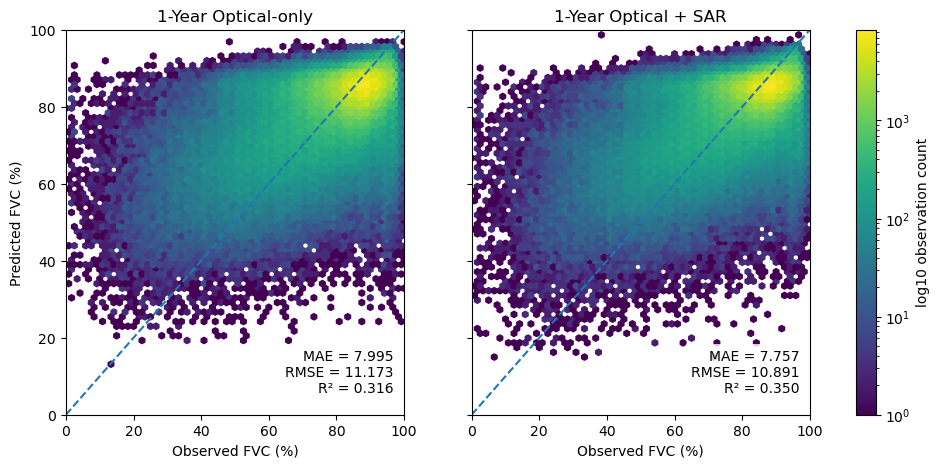

In [59]:
actual_1yr = test_1yr_vis[
    target_variable
].to_numpy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

# Optical-only
hb1 = axes[0].hexbin(
    actual_1yr,
    pred_1yr_optical_vis,
    gridsize=60,
    bins="log",
    mincnt=1
)

axes[0].plot(
    [0, 100],
    [0, 100],
    "--",
    linewidth=1.5
)

axes[0].set_title(
    "1-Year Optical-only"
)

axes[0].set_xlabel(
    "Observed FVC (%)"
)

axes[0].set_ylabel(
    "Predicted FVC (%)"
)

axes[0].text(
    0.97,
    0.05,
    "MAE = 7.995\n"
    "RMSE = 11.173\n"
    "R² = 0.316",
    transform=axes[0].transAxes,
    ha="right",
    va="bottom",
    bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
    )
)


# Optical + SAR
hb2 = axes[1].hexbin(
    actual_1yr,
    pred_1yr_sar_vis,
    gridsize=60,
    bins="log",
    mincnt=1
)

axes[1].plot(
    [0, 100],
    [0, 100],
    "--",
    linewidth=1.5
)

axes[1].set_title(
    "1-Year Optical + SAR"
)

axes[1].set_xlabel(
    "Observed FVC (%)"
)

axes[1].text(
    0.97,
    0.05,
    "MAE = 7.757\n"
    "RMSE = 10.891\n"
    "R² = 0.350",
    transform=axes[1].transAxes,
    ha="right",
    va="bottom",
    bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
    )
)
for ax in axes:
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)

fig.colorbar(
    hb2,
    ax=axes,
    label="log10 observation count"
)

plt.show()

## 8. 5-Year Model Visualisation

The 5-year optical-only and optical-plus-SAR models are visualised using the same independent spatial test blocks as the baseline experiment.

Observed FVC values are compared with predicted FVC values to examine model behaviour over the longer prediction horizon. Hexagonal binning is used because the test dataset contains a large number of pixel-month observations.

The 1:1 reference line represents perfect agreement between observed and predicted FVC.

In [60]:
# Recreate the original 5-year spatial train-test split
train_5yr_vis = samples_5yr_cv[
    samples_5yr_cv["block_id"].isin(train_blocks)
]

test_5yr_vis = samples_5yr_cv[
    samples_5yr_cv["block_id"].isin(test_blocks)
]

print("Training samples:", len(train_5yr_vis))
print("Testing samples:", len(test_5yr_vis))

print(
    "Training blocks:",
    train_5yr_vis["block_id"].nunique()
)

print(
    "Testing blocks:",
    test_5yr_vis["block_id"].nunique()
)

Training samples: 1055820
Testing samples: 286189
Training blocks: 86
Testing blocks: 21


In [61]:
train_5yr_vis_sample = train_5yr_vis.sample(
    n=200_000,
    random_state=42
)

print(
    "Training subset:",
    len(train_5yr_vis_sample)
)

Training subset: 200000


### Refit 5-Year Models for Visualisation

The two 5-year Random Forest models are refitted using the same 200,000 training observations. The optical-only model uses NDVI, EVI and NDRE, while the optical-plus-SAR model additionally includes Sentinel-1 VV and VH.

Predictions are generated only for the independent spatial test blocks.

In [62]:
# Optical-only model
rf_5yr_optical_vis = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_5yr_optical_vis.fit(
    train_5yr_vis_sample[optical_features],
    train_5yr_vis_sample[target_variable]
)

pred_5yr_optical_vis = rf_5yr_optical_vis.predict(
    test_5yr_vis[optical_features]
)


# Optical + SAR model
rf_5yr_sar_vis = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_5yr_sar_vis.fit(
    train_5yr_vis_sample[optical_sar_features],
    train_5yr_vis_sample[target_variable]
)

pred_5yr_sar_vis = rf_5yr_sar_vis.predict(
    test_5yr_vis[optical_sar_features]
)

print("Predictions complete.")
print("Test observations:", len(test_5yr_vis))

Predictions complete.
Test observations: 286189


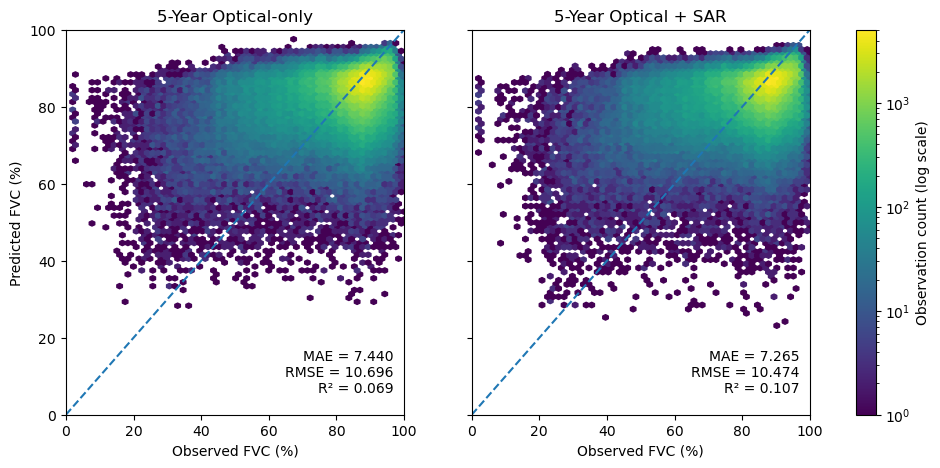

In [63]:
actual_5yr = test_5yr_vis[
    target_variable
].to_numpy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

# Optical-only
hb1 = axes[0].hexbin(
    actual_5yr,
    pred_5yr_optical_vis,
    gridsize=60,
    bins="log",
    mincnt=1
)

axes[0].plot(
    [0, 100],
    [0, 100],
    "--",
    linewidth=1.5
)

axes[0].set_title(
    "5-Year Optical-only"
)

axes[0].set_xlabel(
    "Observed FVC (%)"
)

axes[0].set_ylabel(
    "Predicted FVC (%)"
)

axes[0].text(
    0.97,
    0.05,
    "MAE = 7.440\n"
    "RMSE = 10.696\n"
    "R² = 0.069",
    transform=axes[0].transAxes,
    ha="right",
    va="bottom",
    bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
    )
)


# Optical + SAR
hb2 = axes[1].hexbin(
    actual_5yr,
    pred_5yr_sar_vis,
    gridsize=60,
    bins="log",
    mincnt=1
)

axes[1].plot(
    [0, 100],
    [0, 100],
    "--",
    linewidth=1.5
)

axes[1].set_title(
    "5-Year Optical + SAR"
)

axes[1].set_xlabel(
    "Observed FVC (%)"
)

axes[1].text(
    0.97,
    0.05,
    "MAE = 7.265\n"
    "RMSE = 10.474\n"
    "R² = 0.107",
    transform=axes[1].transAxes,
    ha="right",
    va="bottom",
    bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
    )
)

for ax in axes:
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)

fig.colorbar(
    hb2,
    ax=axes,
    label="Observation count (log scale)"
)

plt.show()

## 9. Spatial Distribution of 1-Year FVC Predictions

The spatial distribution of model predictions is examined for a representative 1-year prediction period. Sentinel-2 and Sentinel-1 observations from June 2023 are used to predict FVC in June 2024.

Only the independent spatial test blocks are displayed. This ensures that the mapped predictions represent locations that were not used for model training.

Prediction error is calculated as:

$$
\mathrm{Error} = \mathrm{Predicted\ FVC} - \mathrm{Observed\ FVC}
$$

Positive errors indicate overprediction, while negative errors indicate underprediction.

In [64]:
target_month = pd.Timestamp("2024-06-01")

month_mask = (
    pd.to_datetime(
        test_1yr_vis["target_date"]
    ) == target_month
)

map_data = test_1yr_vis.loc[
    month_mask,
    ["x", "y", "FVC_target"]
].copy()

map_data["FVC_predicted"] = (
    pred_1yr_sar_vis[
        month_mask.to_numpy()
    ]
)

map_data["Error"] = (
    map_data["FVC_predicted"]
    - map_data["FVC_target"]
)

print("Target month:", target_month.strftime("%Y-%m"))
print("Map observations:", len(map_data))

display(
    map_data[
        ["FVC_target", "FVC_predicted", "Error"]
    ].describe().round(2)
)

Target month: 2024-06
Map observations: 4883


,FVC_target,FVC_predicted,Error
count,4883.00,4883.00,4883.00
mean,85.33,80.54,-4.79
std,11.21,7.24,8.57
min,2.00,34.44,-52.51
25%,85.00,79.00,-8.94
50%,88.50,82.77,-5.58
75%,91.00,84.91,-2.12
max,100.00,92.52,84.06


### Spatial Prediction and Error Maps

The observed FVC, predicted FVC, and prediction error are reconstructed onto the 30 m analysis grid for the selected target month.

Observed and predicted FVC are displayed using the same 0–100% scale to allow direct comparison. Prediction error is displayed using a symmetric range of -30 to +30 percentage points so that spatial patterns in model error can be clearly identified. Values outside this range remain in the data but are saturated at the limits of the displayed colour scale.

In [77]:
# Create 2D spatial grids from the test observations
observed_grid = (
    map_data
    .pivot(index="y", columns="x", values="FVC_target")
    .sort_index(ascending=False)
)

predicted_grid = (
    map_data
    .pivot(index="y", columns="x", values="FVC_predicted")
    .sort_index(ascending=False)
)

error_grid = (
    map_data
    .pivot(index="y", columns="x", values="Error")
    .sort_index(ascending=False)
)

print("Observed grid:", observed_grid.shape)
print("Predicted grid:", predicted_grid.shape)
print("Error grid:", error_grid.shape)

Observed grid: (134, 128)
Predicted grid: (134, 128)
Error grid: (134, 128)


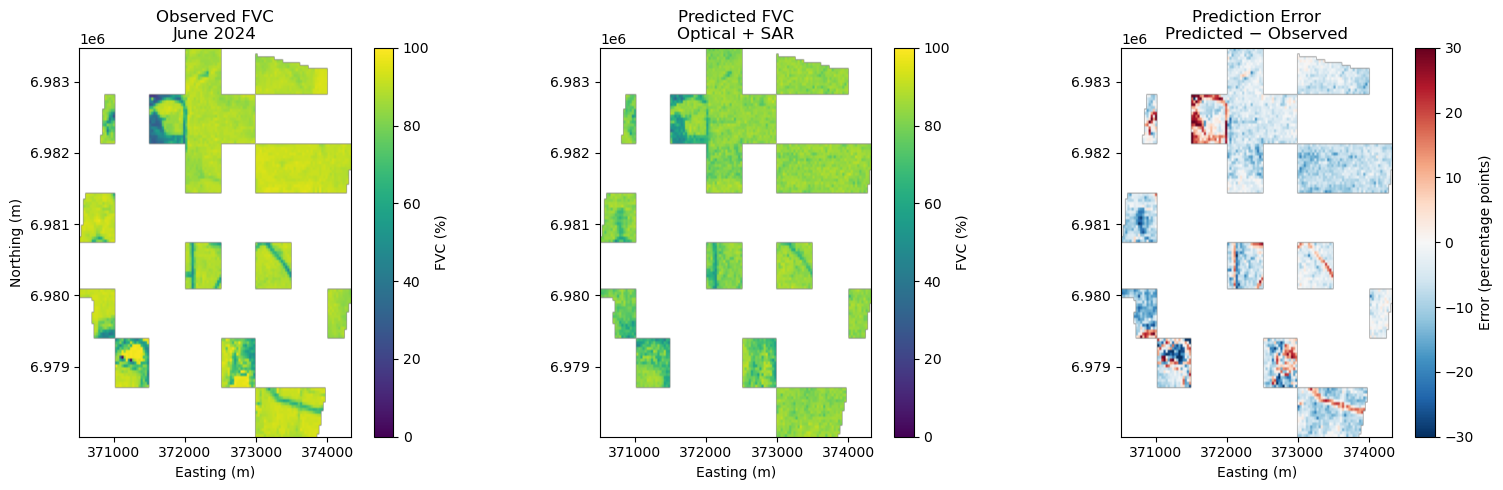

In [78]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

extent = [
    observed_grid.columns.min(),
    observed_grid.columns.max(),
    observed_grid.index.min(),
    observed_grid.index.max()
]

# Observed FVC
im1 = axes[0].imshow(
    observed_grid.values,
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=100
)

axes[0].set_title(
    "Observed FVC\nJune 2024"
)

axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")

fig.colorbar(
    im1,
    ax=axes[0],
    label="FVC (%)"
)


# Predicted FVC
im2 = axes[1].imshow(
    predicted_grid.values,
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=100
)

axes[1].set_title(
    "Predicted FVC\nOptical + SAR"
)

axes[1].set_xlabel("Easting (m)")

fig.colorbar(
    im2,
    ax=axes[1],
    label="FVC (%)"
)


# Prediction error
im3 = axes[2].imshow(
    error_grid.values,
    extent=extent,
    origin="upper",
    vmin=-30,
    vmax=30,
    cmap="RdBu_r"
)

axes[2].set_title(
    "Prediction Error\nPredicted − Observed"
)

axes[2].set_xlabel("Easting (m)")

fig.colorbar(
    im3,
    ax=axes[2],
    label="Error (percentage points)"
)

plt.savefig(
    "FVC_Observed_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()


## 10. Random Forest Feature Importance

Feature importance is examined to investigate the relative contribution of the Sentinel-2 vegetation indices and Sentinel-1 SAR variables to FVC prediction.

The analysis includes NDVI, EVI, NDRE, VV and VH. Feature importance is compared between the 1-year and 5-year optical-plus-SAR models.

Random Forest impurity-based feature importance is first used as a descriptive measure. Because several vegetation indices may be correlated, these importance values should not be interpreted as independent causal contributions.

In [ ]:
# Keep:
# rf_1yr_sar_importance
# rf_5yr_sar_vis
# cv_1yr
# cv_5yr
# importance models

# Remove large datasets no longer needed
# del samples_5yr_cv

# Delete optional intermediate variables only if present.
for _name in [
    "train_5yr_vis", "test_5yr_vis", "train_5yr_vis_sample",
    "train_1yr_vis", "samples_1yr_vis", "pred_1yr_optical_vis"
]:
    globals().pop(_name, None)

import gc
gc.collect()

In [71]:
# Refit the 1-year Optical + SAR model
rf_1yr_sar_importance = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_1yr_sar_importance.fit(
    train_1yr_vis_sample[optical_sar_features],
    train_1yr_vis_sample[target_variable]
)

print("1-year model fitted.")

1-year model fitted.


In [72]:
importance_1yr = pd.DataFrame({
    "Feature": optical_sar_features,
    "Importance": rf_1yr_sar_importance.feature_importances_
})

importance_5yr = pd.DataFrame({
    "Feature": optical_sar_features,
    "Importance": rf_5yr_sar_vis.feature_importances_
})

importance_1yr = importance_1yr.sort_values(
    "Importance",
    ascending=False
)

importance_5yr = importance_5yr.sort_values(
    "Importance",
    ascending=False
)

print("1-year feature importance")
display(
    importance_1yr.round(3)
)

print("5-year feature importance")
display(
    importance_5yr.round(3)
)

1-year feature importance


,Feature,Importance
1,EVI,0.415
0,NDVI,0.167
3,VV,0.152
4,VH,0.137
2,NDRE,0.128


5-year feature importance


,Feature,Importance
1,EVI,0.317
4,VH,0.181
0,NDVI,0.176
2,NDRE,0.164
3,VV,0.163


In [84]:
for name in [
    "rf_1yr_sar_importance",
    "rf_1yr_sar_vis",
    "rf_5yr_sar_vis"
]:
    print(name, name in globals())

rf_1yr_sar_importance True
rf_1yr_sar_vis False
rf_5yr_sar_vis True


In [85]:
import joblib

joblib.dump(
    rf_1yr_sar_importance,
    "rf_1year_sar_importance.joblib",
    compress=3
)

importance_1yr = pd.DataFrame({
    "Feature": ["NDVI", "EVI", "NDRE", "VV", "VH"],
    "Importance": rf_1yr_sar_importance.feature_importances_
})

importance_1yr.to_csv(
    "feature_importance_1year.csv",
    index=False
)

display(importance_1yr)

,Feature,Importance
0,NDVI,0.167389
1,EVI,0.415401
2,NDRE,0.128207
3,VV,0.151732
4,VH,0.137271


In [89]:
variables = [
    "samples_1yr",
    "samples_1yr_cv",
    "samples_1yr_vis",
    "test_1yr_vis",
    "test_idx",
    "rf_1yr_sar_importance",
    "rf_1yr_sar_vis",
    "pred_1yr_sar_vis"
]

for name in variables:
    print(f"{name}: {name in globals()}")

samples_1yr: False
samples_1yr_cv: False
samples_1yr_vis: False
test_1yr_vis: True
test_idx: True
rf_1yr_sar_importance: True
rf_1yr_sar_vis: False
pred_1yr_sar_vis: True


In [90]:
predictions_1yr = test_1yr_vis[
    [
        "x",
        "y",
        "predictor_date",
        "target_date",
        "block_id",
        "FVC_target"
    ]
].copy()

predictions_1yr["FVC_pred_optical_sar"] = (
    pred_1yr_sar_vis
)

predictions_1yr.to_csv(
    "predictions_1year_test.csv",
    index=False
)

print("1-year predictions saved.")
print("Observations:", len(predictions_1yr))

1-year predictions saved.
Observations: 518615


In [91]:
importance_1yr = pd.DataFrame({
    "Feature": ["NDVI", "EVI", "NDRE", "VV", "VH"],
    "Importance": rf_1yr_sar_importance.feature_importances_
})

importance_1yr.to_csv(
    "feature_importance_1year.csv",
    index=False
)

display(importance_1yr.round(4))

,Feature,Importance
0,NDVI,0.1674
1,EVI,0.4154
2,NDRE,0.1282
3,VV,0.1517
4,VH,0.1373


In [92]:
import joblib

joblib.dump(
    rf_1yr_sar_importance,
    "rf_1year_sar_importance.joblib",
    compress=3
)

print("1-year Random Forest saved.")

1-year Random Forest saved.


In [93]:
variables_5yr = [
    "test_5yr_vis",
    "pred_5yr_sar_vis",
    "rf_5yr_sar_vis",
    "rf_5yr_sar_importance",
    "samples_5yr_cv"
]

for name in variables_5yr:
    print(f"{name}: {name in globals()}")

test_5yr_vis: False
pred_5yr_sar_vis: True
rf_5yr_sar_vis: True
rf_5yr_sar_importance: False
samples_5yr_cv: False


### Save 5-Year Spatial Predictions

The previously generated 5-year optical-plus-SAR predictions are saved alongside the corresponding observed FVC values and spatial coordinates.

These results will be used for spatial prediction and error visualisation without repeating model training.

In [95]:
import joblib

joblib.dump(
    rf_5yr_sar_vis,
    "rf_5year_sar.joblib",
    compress=3
)

print("5-year Random Forest saved.")

5-year Random Forest saved.


In [96]:
importance_5yr = pd.DataFrame({
    "Feature": ["NDVI", "EVI", "NDRE", "VV", "VH"],
    "Importance": rf_5yr_sar_vis.feature_importances_
})

importance_5yr.to_csv(
    "feature_importance_5year.csv",
    index=False
)

display(importance_5yr.round(4))

,Feature,Importance
0,NDVI,0.1755
1,EVI,0.3170
2,NDRE,0.1638
3,VV,0.1625
4,VH,0.1811


In [97]:
for name in sorted(globals()):
    if (
        "5yr" in name.lower()
        or "5year" in name.lower()
    ):
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            print(name, obj.shape)
        elif isinstance(obj, np.ndarray):
            print(name, obj.shape)
        else:
            print(name, type(obj).__name__)

actual_5yr (286189,)
cv_5yr (5, 10)
importance_5yr (5, 2)
mae_change_5yr float
metrics_5yr_optical dict
metrics_5yr_optical_saved dict
metrics_5yr_sar dict
overlap_5yr set
pairs_5yr list
pred_5yr_optical_vis (286189,)
pred_5yr_sar_vis (286189,)
r2_change_5yr float
rf_5yr_optical_vis RandomForestRegressor
rf_5yr_sar_vis RandomForestRegressor
rmse_change_5yr float64
test_5yr (286189, 13)
train_5yr_sample (200000, 13)
variables_5yr list


In [98]:
# Check prediction and test data dimensions
assert len(test_5yr) == len(pred_5yr_sar_vis)
assert len(test_5yr) == len(pred_5yr_optical_vis)

# Save existing test observations
predictions_5yr = test_5yr[
    [
        "x",
        "y",
        "predictor_date",
        "target_date",
        "block_id",
        "FVC_target"
    ]
].copy()

# Add existing predictions
predictions_5yr["FVC_pred_optical"] = (
    pred_5yr_optical_vis
)

predictions_5yr["FVC_pred_optical_sar"] = (
    pred_5yr_sar_vis
)

# Save to CSV
predictions_5yr.to_csv(
    "predictions_5year_test.csv",
    index=False
)

print("5-year predictions saved.")
print("Observations:", len(predictions_5yr))

5-year predictions saved.
Observations: 286189


In [99]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = predictions_5yr["FVC_target"]
predicted = predictions_5yr["FVC_pred_optical_sar"]

print("5-year Optical + SAR")
print("--------------------")

print(
    "MAE:",
    round(mean_absolute_error(actual, predicted), 3)
)

print(
    "RMSE:",
    round(
        np.sqrt(mean_squared_error(actual, predicted)),
        3
    )
)

print(
    "R²:",
    round(r2_score(actual, predicted), 3)
)

5-year Optical + SAR
--------------------
MAE: 7.265
RMSE: 10.474
R²: 0.107


In [100]:
from pathlib import Path

files_to_check = [
    "predictions_1year_test.csv",
    "predictions_5year_test.csv",
    "feature_importance_1year.csv",
    "feature_importance_5year.csv",
    "rf_1year_sar_importance.joblib",
    "rf_5year_sar.joblib"
]

for filename in files_to_check:
    print(
        filename,
        "FOUND" if Path(filename).exists() else "NOT FOUND"
    )

predictions_1year_test.csv FOUND
predictions_5year_test.csv FOUND
feature_importance_1year.csv FOUND
feature_importance_5year.csv FOUND
rf_1year_sar_importance.joblib FOUND
rf_5year_sar.joblib FOUND
